# geosplat: photos ➜ orthophoto, point cloud, Gaussian splat

<a href="https://colab.research.google.com/github/GeomaticsCaminosUPM/geosplat/blob/main/examples/run.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

Turns a folder of photos into a **fast orthophoto**, a **point cloud**, a **Gaussian splat** and a **true
orthophoto + DSM**. If the photos have GPS, everything is read from their metadata (positions, UTM zone) and shown
on Google maps; a `name,x,y,z` CSV in the photo folder is used as ground control points. Without GPS, everything
except the maps still runs.

**Use:** pick a GPU runtime (*Runtime ▸ Change runtime type ▸ GPU*), set the 3 options in section 2, then
*Runtime ▸ Run all*.

## 1. Setup

Installs (or refreshes) `geosplat`: from your local clone if the notebook is inside one, otherwise from GitHub. It
then reloads it, so the current code is used without restarting the kernel, and checks that every stage runs on the
GPU.

In [1]:
import importlib, importlib.util, os, shutil, subprocess, sys, time
from pathlib import Path

REPO_URL = "https://github.com/GeomaticsCaminosUPM/geosplat.git"
REINSTALL = True          # always (re)install the latest geosplat code and reload it

def find_repo():
    """Return the local geosplat repository containing the working directory, if any."""
    for d in [Path.cwd(), *Path.cwd().parents]:
        if (d / "pyproject.toml").is_file() and 'name = "geosplat"' in (d / "pyproject.toml").read_text():
            return d
    return None

repo = find_repo()
spec = ["-e", str(repo)] if repo else [f"geosplat @ git+{REPO_URL}"]     # local clone: editable install
pip = ["uv", "pip", "install", "--python", sys.executable] if shutil.which("uv") else [sys.executable, "-m", "pip", "install"]
if importlib.util.find_spec("geosplat") is None:
    subprocess.run(pip + ["-q", *spec, "ipyleaflet"], check=True)          # first install, with dependencies
elif REINSTALL:
    subprocess.run(pip + ["-q", "--force-reinstall", "--no-deps", *spec], check=True)   # refresh geosplat only

for name in [m for m in sys.modules if m == "geosplat" or m.startswith("geosplat.")]:
    del sys.modules[name]                                                   # drop old code from this kernel
importlib.invalidate_caches()
import geosplat

pkg = Path(geosplat.__file__).parent
newest = max(f.stat().st_mtime for f in pkg.glob("*.py"))
print(f"geosplat {geosplat.__version__} from {pkg} (code modified {time.strftime('%Y-%m-%d %H:%M', time.localtime(newest))})")
if repo:
    os.chdir(repo)                                    # paths like examples/... are relative to the repo

try:                                                  # interactive maps on Colab
    from google.colab import output
    output.enable_custom_widget_manager()
except ImportError:
    pass

import logging
import pycolmap
import torch

logging.basicConfig(level=logging.INFO, format="%(asctime)s %(message)s", force=True)
gpu = {
    "torch (training, orthophotos)": torch.cuda.is_available(),
    "COLMAP (features, matching, BA)": bool(getattr(pycolmap, "has_cuda", False)),
    "gsplat rasterizer": geosplat.gsplat_available(),   # first call compiles CUDA kernels (3-5 min)
}
print("GPU:", torch.cuda.get_device_name(0) if torch.cuda.is_available() else "none")
for stage, ok in gpu.items():
    print(f"  {'GPU' if ok else 'CPU!':4}  {stage}")
if not all(gpu.values()):
    print("\nSome stages would run on the CPU (very slow).",
          "Colab: Runtime > Change runtime type > GPU, then restart.",
          "Local: NVIDIA driver + CUDA toolkit (nvcc) and a CUDA build of torch (uv sync does this).")
print("\ngeosplat", geosplat.__version__, "| working dir:", Path.cwd())

2026-11-19 02:35:20,739 Checking gsplat CUDA backend (first run compiles kernels, may take minutes)...


geosplat 0.1.0 from /home/miguel/Documents/Proyectos/GaussianSplatting/src/geosplat (code modified 2026-11-19 02:28)
GPU: NVIDIA GeForce RTX 4060 Laptop GPU
  GPU   torch (training, orthophotos)
  GPU   COLMAP (features, matching, BA)
  GPU   gsplat rasterizer

geosplat 0.1.0 | working dir: /home/miguel/Documents/Proyectos/GaussianSplatting


## 2. Options

| Option | Meaning |
|---|---|
| `IMAGES_DIR` | Folder with the photos (JPG/PNG). **For your own images, point it to your folder.** On Colab, upload the photos or mount Google Drive first (e.g. `/content/drive/MyDrive/flight1`). |
| `OUTPUT_DIR` | Where results go. Default: `<IMAGES_DIR>/../output_<PRESET>`. |
| `PRESET` | Speed/quality, see below. |
| `SAMPLE` | Demo photos, downloaded **only if `IMAGES_DIR` has no photos**: `"seneca"` (drone, GPS) or `"south_building"` (hand-held, no GPS). Ignored when your folder has photos. |

| `PRESET` | Time on Colab* | Use it for |
|---|---|---|
| `very_fast` | ~2 min | check that everything works |
| `fast` | ~5 min | previews |
| `medium` | ~25 min | good results (default) |
| `quality` | ~1.5 h | final products |

\*Estimated for 50 photos on a Colab T4 GPU, plus ~5–8 min of one-time setup per session (install + CUDA
build). A local RTX 4060 is about 2× faster.

In [3]:
IMAGES_DIR = Path("examples/dron2024/images")   # your photos, e.g. Path("/content/drive/MyDrive/flight1")
OUTPUT_DIR = None          # None -> IMAGES_DIR.parent / f"output_{PRESET}"
PRESET = "very_fast"            # "very_fast" | "fast" | "medium" | "quality"
SAMPLE = "seneca"          # demo photos if IMAGES_DIR is empty: "seneca" | "south_building" | None

from geosplat import datasets
has_photos = IMAGES_DIR.is_dir() and any(p.suffix.lower() in (".jpg", ".jpeg", ".png") for p in IMAGES_DIR.iterdir())
if not has_photos and SAMPLE == "seneca":
    datasets.download_seneca(IMAGES_DIR, num_images=40)
elif not has_photos and SAMPLE == "south_building":
    datasets.download_south_building(IMAGES_DIR, num_images=40)

OUTPUT_DIR = Path(OUTPUT_DIR or IMAGES_DIR.parent / f"output_{PRESET}")
sfm_cfg, train_cfg, geo_cfg = geosplat.make_configs(PRESET)
photos = geosplat.sfm.list_images(IMAGES_DIR)
n_gps = sum(geosplat.geo.read_gps(p) is not None for p in photos)
GEO = n_gps >= 3
print(f"{len(photos)} photos, {n_gps} with GPS -> {'georeferenced mode' if GEO else 'local mode (no maps)'}")
print("outputs ->", OUTPUT_DIR)

40 photos, 40 with GPS -> georeferenced mode
outputs -> examples/dron2024/output_very_fast


## 3. Photos

With GPS, the map shows each photo: ■ straight down, camera symbol = oblique (cone toward the view), ● no direction
data. All photos are included (pink) by default. **Optional:** choose *Include* or *Exclude* and draw a polygon or
rectangle (toolbar, left) to apply it to the photos inside; click a photo to toggle it, or use the buttons. Excluded
photos are grey. Then run the next cell.

In [4]:
from geosplat import plots

selector = plots.photos(IMAGES_DIR, selection_file=OUTPUT_DIR / "selection.txt")   # None without GPS

## 4. Camera poses (COLMAP)

Runs on the GPU and is cached in `OUTPUT_DIR/colmap/`. Only the photos included on the map are used.

In [5]:
import time
from geosplat.geo import local_georeference
from geosplat.pipeline import prepare_scene

OUTPUT_DIR.mkdir(parents=True, exist_ok=True)
if selector is not None and not selector.all_selected:
    sfm_cfg.image_list = [p.name for p in selector.selected]
    print(f"Using {len(selector.selected)} of {len(selector.photos)} photos")

timings = {}
t = time.time()
colmap_dir = geosplat.run_sfm(IMAGES_DIR, OUTPUT_DIR / "colmap", sfm_cfg)
scene, geo = prepare_scene(colmap_dir, IMAGES_DIR, geo_cfg)
timings["colmap"] = time.time() - t
geo_gps = geo                                     # georeference from photo GPS (kept for the GCP step)
frame = geo or local_georeference(scene)          # map frame for orthophotos (local if no GPS)
gcp_file = geosplat.geo.find_gcp_file(IMAGES_DIR) if geo else None   # name,x,y,z CSV next to the photos
gcp_pts = geosplat.geo.read_gcps(gcp_file) if gcp_file else None
if geo:
    geo.save(OUTPUT_DIR / "geo.json")
print(f"{len(scene.cameras)} cameras, {len(scene.points)} points, {timings['colmap']:.0f} s"
      + (f" | {geo.crs}, GPS fit {geo.rmse:.1f} m" if geo else "")
      + (f" | GCPs: {gcp_file.name}" if gcp_file else ""))

2026-11-19 02:35:59,480 Reusing existing SfM result in examples/dron2024/output_very_fast/colmap/undistorted
2026-11-19 02:35:59,585 Georeferenced 40 cameras to EPSG:32630 (camera RMSE 1.60 m)
2026-11-19 02:35:59,589 Ground control points found: targets.csv


40 cameras, 10173 points, 0 s | EPSG:32630, GPS fit 1.6 m | GCPs: targets.csv


## 5. Fast orthophoto

Seconds after COLMAP. Built on the sparse points: flat ground is right, while tall objects lean.

In [6]:
t = time.time()
fast = geosplat.make_fast_orthophoto(scene, frame, OUTPUT_DIR / "fast_orto", gcps=gcp_file)
timings["fast_orto"] = time.time() - t
print(fast["fast_orto"], f"({fast['gsd']:.3f} units/px)")
plots.ortho(fast["fast_orto"], gcps=gcp_pts)

2026-11-19 02:36:02,387 fast_orto grid 1410x1699 at 0.055 m/px


examples/dron2024/output_very_fast/fast_orto/fast_orto.tif (0.055 units/px)


## 6. Gaussian splat (training)

The progress bar shows the loss and the number of Gaussians (`n`).

In [7]:
t = time.time()
result = geosplat.Trainer(scene, OUTPUT_DIR, train_cfg).train()
timings["train"] = time.time() - t
print(result.metrics)

2026-11-19 02:36:05,540 Checking gsplat CUDA backend (first run compiles kernels, may take minutes)...
2026-11-19 02:36:05,542 Training on cuda with the gsplat backend
2026-11-19 02:36:05,794 35 training / 5 test images
2026-11-19 02:36:05,830 Added 17296 background-sphere points at radius 11.61
2026-11-19 02:36:06,054 Initialized 27469 Gaussians


Training:   0%|          | 0/1000 [00:00<?, ?it/s]

2026-11-19 02:36:23,386 Saved examples/dron2024/output_very_fast/splat.ply | {'psnr': 17.035295469902376, 'ssim': 0.42432735562324525, 'eval_split': 'test', 'num_gaussians': 46975, 'train_seconds': 16.06891131401062, 'steps': 1000}


{'psnr': 17.035295469902376, 'ssim': 0.42432735562324525, 'eval_split': 'test', 'num_gaussians': 46975, 'train_seconds': 16.06891131401062, 'steps': 1000}


## 7. Ground control points (optional)

Only with GPS photos and a `name,x,y,z` CSV next to them (a header row is fine). The map shows the true orthophoto.
Choose a point and **click its target** to place a pink ✕; do this for at least 3 points. Drag a ✕ to move it, or
use the buttons to delete or clear. Then run the next cell and the ones after it; the final products then use the
GCP georeference. Without picks, the photo GPS is used.

In [8]:
picker = None
if GEO and gcp_pts:
    from geosplat.gcp import GCPPicker
    ortho_gps = geosplat.make_orthophoto(result.params, scene, geo_gps, OUTPUT_DIR / "gcp" / "ortho_gps",
                                         result.sh_degree, gcps=gcp_file)
    picker = GCPPicker(ortho_gps["orthophoto"], gcp_pts, picks_file=OUTPUT_DIR / "gcp" / "picks.json")
    display(picker)
else:
    print("Skipped: needs GPS photos and a GCP CSV in", IMAGES_DIR)

2026-11-19 02:36:23,447 Orthophoto grid 1410x1699 at 0.055 m/px
2026-11-19 02:36:24,943 DSM minus GCP height (m): {'D1': -6.79, 'D2': -6.85, 'D3': -6.74, 'D4': -5.67}


In [9]:
geo = geo_gps                                     # re-running is safe: always start from the GPS georeference
if picker is not None and picker.picks:
    from geosplat.gcp import refine_georeference
    geo, report = refine_georeference(geo_gps, picker.picks, gcp_pts, ortho_gps["dsm"])
    geo_gps.save(OUTPUT_DIR / "gcp" / "geo_gps.json")
    print(f"{report['method']} from {report['points']} points | RMSE xy {report['rmse_xy_m']:.3f} m, "
          f"z {report['rmse_z_m']:.3f} m | scale change {report['scale_change']:.5f}")
    print("residuals (m):", report["residuals_m"])
elif picker is not None:
    print("No points placed: using the photo GPS. Place points above, then run this cell and the next ones.")
frame = geo or local_georeference(scene)
if geo:
    geo.save(OUTPUT_DIR / "geo.json")

similarity (7 parameters) from 3 points | RMSE xy 0.017 m, z 0.001 m | scale change 0.98643
residuals (m): {'D1': [-0.006, 0.014, 0.001], 'D2': [0.018, -0.002, -0.001], 'D3': [-0.012, -0.012, -0.0]}


## 8. Final products

The fast orthophoto, true orthophoto + DSM and point clouds are written with the final georeference (GCPs if
placed, otherwise GPS). The true orthophoto reprojects the photos onto the splat surface with occlusion checks, so
walls and trees stand upright.

In [10]:
t = time.time()
fast = geosplat.make_fast_orthophoto(scene, frame, OUTPUT_DIR / "fast_orto", gcps=gcp_file)
ortho = geosplat.make_orthophoto(result.params, scene, frame, OUTPUT_DIR / "ortho", result.sh_degree, gcps=gcp_file)
clouds = geosplat.export_point_clouds(result.params, scene, OUTPUT_DIR, geo,
                                      min_opacity=geo_cfg.dense_min_opacity)   # "auto" or e.g. 0.5
geosplat.save_viewer(result.params, OUTPUT_DIR / "viewer.html", result.train_cameras)
timings["products"] = time.time() - t
print(ortho["orthophoto"], "|", ortho["dsm"], "|", clouds["points_dense"])
if "gcp_dz" in ortho:
    print("DSM minus GCP height (m):", {k: round(v, 2) for k, v in ortho["gcp_dz"].items()})

2026-11-19 02:37:25,265 fast_orto grid 1415x1703 at 0.054 m/px
2026-11-19 02:37:25,842 Orthophoto grid 1415x1703 at 0.054 m/px
2026-11-19 02:37:26,594 DSM minus GCP height (m): {'D1': -0.0, 'D2': 0.02, 'D3': 0.0, 'D4': -0.88}
2026-11-19 02:37:26,601 Dense point cloud: automatic opacity threshold 0.50


examples/dron2024/output_very_fast/ortho/orthophoto.tif | examples/dron2024/output_very_fast/ortho/dsm.tif | examples/dron2024/output_very_fast/points_dense.ply
DSM minus GCP height (m): {'D1': -0.0, 'D2': 0.02, 'D3': 0.0, 'D4': -0.88}


## 9. Results

### Gaussian splat (drag: orbit, right-drag: pan, wheel: zoom)

In [11]:
plots.splat(result.params, result.train_cameras)

/home/miguel/Documents/Proyectos/GaussianSplatting/.venv/lib/python3.12/site-packages/IPython/core/display.py:448: UserWarning: Consider using IPython.display.IFrame instead
  warnings.warn("Consider using IPython.display.IFrame instead")


### Point cloud

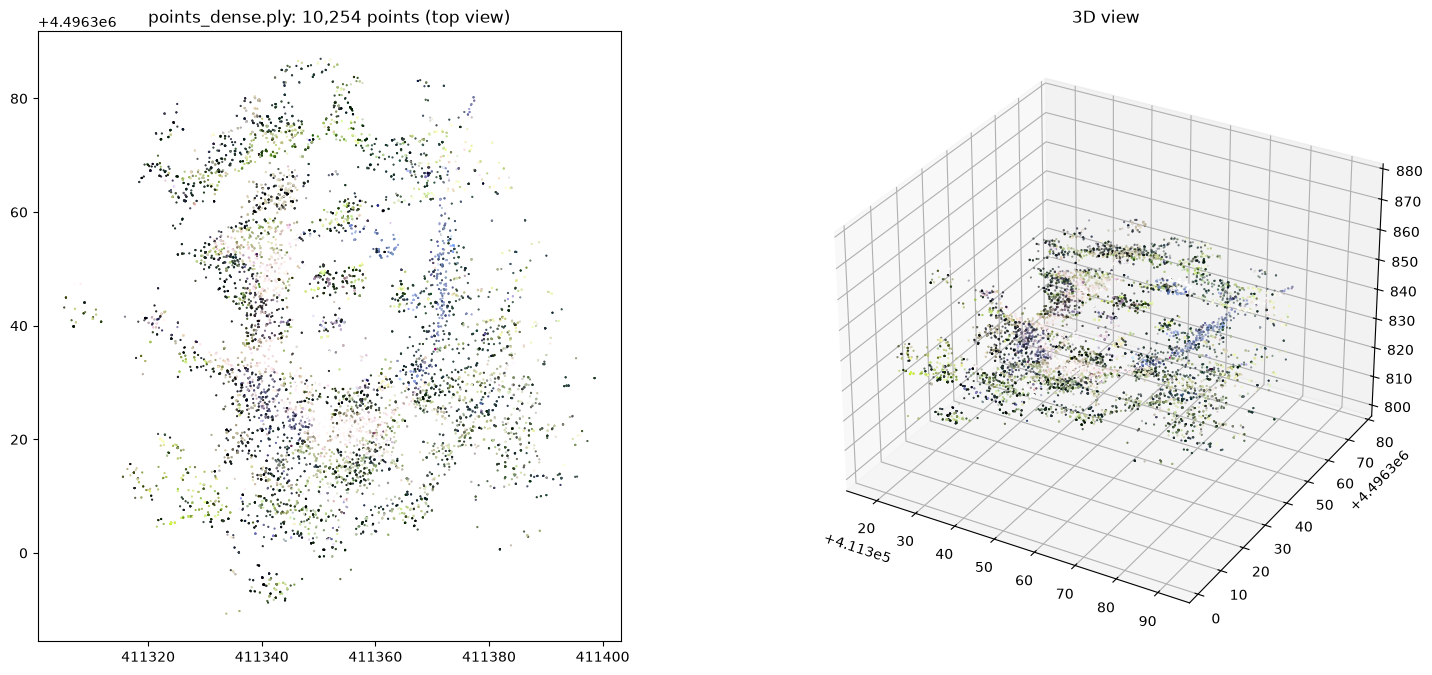

In [12]:
plots.point_cloud(clouds["points_dense"])

### True orthophoto

In [13]:
plots.ortho(ortho["orthophoto"], gcps=gcp_pts)

## 10. Output files

| File in `OUTPUT_DIR` | What it is | Open with |
|---|---|---|
| `fast_orto/fast_orto.tif` | first orthophoto (GeoTIFF) | QGIS |
| `ortho/orthophoto.tif`, `ortho/dsm.tif` | true orthophoto, surface model | QGIS |
| `points_sparse.ply`, `points_dense.ply` | colored point clouds | CloudCompare |
| `splat.ply` | Gaussian splat | [SuperSplat](https://superspl.at/editor) |
| `viewer.html` | interactive splat viewer | any browser |
| `geo.json`, `metrics.json`, `timings.json` | georeference, quality, times | text editor |
| `gcp/picks.json`, `gcp/geo_gps.json`, `gcp/ortho_gps/` | GCP picks, GPS-only georeference and orthophoto (section 7) | text editor / QGIS |

With GPS, rasters and point clouds use real coordinates (auto UTM zone). Without GPS they are in a local frame.
The next cell zips the results (without `colmap/`) and downloads them on Colab.

In [14]:
import json, shutil, zipfile

timings["total"] = sum(timings.values())
(OUTPUT_DIR / "timings.json").write_text(json.dumps(timings, indent=2))
print({k: round(v) for k, v in timings.items()}, "seconds")

zip_path = OUTPUT_DIR.with_suffix(".zip")
with zipfile.ZipFile(zip_path, "w", zipfile.ZIP_DEFLATED) as zf:
    for f in OUTPUT_DIR.rglob("*"):
        if f.is_file() and "colmap" not in f.relative_to(OUTPUT_DIR).parts:
            zf.write(f, f.relative_to(OUTPUT_DIR))
print(zip_path, f"{zip_path.stat().st_size / 1e6:.0f} MB")
try:
    from google.colab import files
    files.download(str(zip_path))
except ImportError:
    pass

{'colmap': 0, 'fast_orto': 1, 'train': 18, 'products': 1, 'total': 20} seconds
examples/dron2024/output_very_fast.zip 65 MB
